# 01 – First look at the three data sources

**Goal:** show that we can load all three data sources and put them side by side.

For **one** forecast (started 1 October 2026, 00 UTC) at **one** station (Hamburg-Fuhlsbüttel) we load

1. the **AIFS ENS** forecast (ECMWF's neural-network ensemble),
2. the **IFS ENS** forecast (ECMWF's physics-based ensemble),
3. the **DWD** measurement (what the temperature really was),

and plot the 2 m temperature for the 15 days after the start.

The forecast data is read directly from the cloud: only the small piece we select is downloaded.
The DWD file is saved in `data/dwd/`.

## 0. Setup

The settings at the top are the only things you need to change to look at another forecast or station.

In [2]:
import time
import urllib.request
import zipfile
from pathlib import Path

import dynamical_catalog
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Settings: change these to look at another forecast or station ---
INIT_TIME = pd.Timestamp("2026-10-01T00:00")  # start time of the forecast (UTC); must be a 00 UTC start
STATION_ID = "01975"                           # DWD station ID
STATION_NAME = "Hamburg-Fuhlsbüttel"
STATION_LAT, STATION_LON = 53.6332, 9.9881     # station position in degrees north / east

# Folders: find the repository root (the folder that contains pyproject.toml)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = REPO_ROOT / "data"
FIGURE_DIR = REPO_ROOT / "docs" / "figures"

## 1. AIFS ENS (neural network)

`dynamical_catalog.open(...)` opens the dataset **lazily**: it only reads the *description* of the dataset
(which variables, dimensions and coordinates exist), not the values themselves.
Values are downloaded only when we call `.load()` later.
`chunks=None` tells xarray to read the data directly, without splitting the work into parallel pieces (Dask);
for small selections like ours this is the simplest option.

The output below shows the dataset's five **dimensions**:

- `init_time`: when the forecast was started,
- `lead_time`: how far ahead of the start a value is (0 h, 6 h, 12 h, …, 360 h),
- `ensemble_member`: which of the 51 forecasts (0 = control run, 1–50 = runs from slightly changed starting states),
- `latitude`, `longitude`: the grid point.

It also has the coordinate `valid_time = init_time + lead_time`: the point in time the value is a forecast *for*.

In [3]:
aifs_ds = dynamical_catalog.open("ecmwf-aifs-ens-forecast", chunks=None)
aifs_ds

<xarray.Dataset> Size: 424TB
Dimensions:                                     (init_time: 1930,
                                                 lead_time: 61,
                                                 ensemble_member: 51,
                                                 latitude: 721, longitude: 1440)
Coordinates:
  * init_time                                   (init_time) datetime64[ns] 15kB ...
    expected_forecast_length                    (init_time) timedelta64[us] 15kB ...
    ingested_forecast_length                    (init_time) timedelta64[us] 15kB ...
  * lead_time                                   (lead_time) timedelta64[us] 488B ...
    valid_time                                  (init_time, lead_time) datetime64[ns] 942kB ...
  * ensemble_member                             (ensemble_member) int16 102B ...
  * latitude                                    (latitude) float64 6kB 90.0 ....
  * longitude                                   (longitude) float64 12kB -180...
    spatial_ref                                 int64 8B ...
Data variables: (12/17)
    downward_short_wave_radiation_flux_surface  (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    downward_long_wave_radiation_flux_surface   (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    dew_point_temperature_2m                    (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    geopotential_height_500hpa                  (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    geopotential_height_850hpa                  (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    geopotential_height_925hpa                  (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    ...                                          ...
    temperature_850hpa                          (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    total_cloud_cover_atmosphere                (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    wind_u_100m                                 (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    wind_u_10m                                  (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    wind_v_10m                                  (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
    wind_v_100m                                 (init_time, lead_time, ensemble_member, latitude, longitude) float32 25TB ...
Attributes:
    dataset_id:           ecmwf-aifs-ens-forecast
    dataset_version:      0.1.0
    name:                 ECMWF AIFS ENS forecast
    description:          Ensemble weather forecasts from the ECMWF Artificia...
    attribution:          ECMWF AIFS ENS forecast data processed by dynamical...
    license:              CC-BY-4.0
    spatial_domain:       Global
    spatial_resolution:   0.25 degrees (~20km)
    time_domain:          Forecasts initialized 2025-07-02 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-360 hours (0-15 days) ahead
    forecast_resolution:  6 hourly

Now we pick out one forecast at the grid point nearest to the station.
`method="nearest"` takes the closest grid point. The grid spacing is 0.25°, which at Hamburg is
about 28 km north–south and 17 km east–west, so the grid point is up to a few kilometres away from the station.
(Later we will interpolate between the four surrounding grid points instead.)

We write this as a small function because we need exactly the same steps for the IFS.

In [4]:
def point_forecast(ds, variable):
    # One forecast (all lead times, all 51 members) at the grid point nearest to the station.
    return (
        ds[variable]
        .sel(init_time=INIT_TIME)  # exact start time: raises an error if this forecast does not exist
        .sel(latitude=STATION_LAT, longitude=STATION_LON, method="nearest")
        .load()  # this is where the data is actually downloaded
    )


aifs_t2m = point_forecast(aifs_ds, "temperature_2m")

print(f"Nearest grid point: {float(aifs_t2m.latitude):.2f}°N, {float(aifs_t2m.longitude):.2f}°E")
print("Shape:", dict(aifs_t2m.sizes))

Nearest grid point: 53.75°N, 10.00°E
Shape: {'lead_time': 61, 'ensemble_member': 51}


## 2. IFS ENS (physics)

Same steps. The one difference is the time step **within** a forecast:
the IFS has a value every 3 h up to +144 h and every 6 h after that, while AIFS only has a value every 6 h.
So we first look at the IFS lead times, then keep only those that AIFS also has.
After that, both forecasts have the same 61 lead times (0 h, 6 h, …, 360 h).

In [5]:
ifs_ds = dynamical_catalog.open("ecmwf-ifs-ens-forecast-15-day-0-25-degree", chunks=None)
ifs_t2m = point_forecast(ifs_ds, "temperature_2m")

ifs_lead_hours = (ifs_t2m.lead_time.values / np.timedelta64(1, "h")).astype(int)
print(f"IFS lead times (h): {ifs_lead_hours[:8]} ... {ifs_lead_hours[-4:]}  ({len(ifs_lead_hours)} in total)")

# Keep only the lead times AIFS also has, and check that both now describe the same points in time
ifs_t2m = ifs_t2m.sel(lead_time=aifs_t2m.lead_time)
assert (ifs_t2m.valid_time.values == aifs_t2m.valid_time.values).all()
print(f"After matching: {ifs_t2m.sizes['lead_time']} lead times in both models")

IFS lead times (h): [ 0  3  6  9 12 15 18 21] ... [342 348 354 360]  (85 in total)
After matching: 61 lead times in both models


## 3. DWD station measurements

The DWD publishes one zip file per station and variable.
The folder `recent/` holds the latest data (updated daily); older data is in `historical/`.
We download the file once and keep it in `data/dwd/` (it is downloaded again if it is older than one day).

Inside the zip, the measurements are in the file whose name starts with `produkt`.
It is a text table separated by `;` with these columns:

| Column | Meaning |
|---|---|
| `STATIONS_ID` | station ID |
| `MESS_DATUM` | time of measurement, written as `YYYYMMDDHH`, in UTC |
| `QN_9` | quality level of the row |
| `TT_TU` | air temperature at 2 m height, in °C |
| `RF_TU` | relative humidity, in % |
| `eor` | "end of record" marker |

Missing values are written as `-999`.

In [6]:
dwd_url = (
    "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/"
    f"hourly/air_temperature/recent/stundenwerte_TU_{STATION_ID}_akt.zip"
)
zip_path = DATA_DIR / "dwd" / f"stundenwerte_TU_{STATION_ID}_akt.zip"

one_day = 24 * 3600
# Download the DWD data if it does not exist or is older than one day
if not zip_path.exists() or time.time() - zip_path.stat().st_mtime > one_day:
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(dwd_url, zip_path) # Download the file from the DWD URL and save it to the specified path

# Read the DWD data from the zip file
with zipfile.ZipFile(zip_path) as zf:
    # filter the "produkt..." file, which contains the actual measurement data
    product_file = next(name for name in zf.namelist() if name.startswith("produkt"))
    with zf.open(product_file) as f:
        # convert the txt text into a pandas dataframe
        dwd = pd.read_csv(f, sep=";", skipinitialspace=True, na_values=[-999], encoding="latin-1")

dwd["time"] = pd.to_datetime(dwd["MESS_DATUM"].astype(str), format="%Y%m%d%H") # Turn the MESS_DATUM column into a datetime object and store it in a new column called 'time'
print(f"File {product_file}: {len(dwd)} hourly rows from {dwd['time'].min()} to {dwd['time'].max()}")
dwd.head()

File produkt_tu_stunde_20250424_20261025_01975.txt: 13200 hourly rows from 2025-04-24 00:00:00 to 2026-10-25 23:00:00


,STATIONS_ID,MESS_DATUM,QN_9,TT_TU,RF_TU,eor,time
0,1975,2025042400,3,10.9,80.0,eor,2025-04-24 00:00:00
1,1975,2025042401,3,10.7,83.0,eor,2025-04-24 01:00:00
2,1975,2025042402,3,10.5,84.0,eor,2025-04-24 02:00:00
3,1975,2025042403,3,10.3,86.0,eor,2025-04-24 03:00:00
4,1975,2025042404,3,10.1,88.0,eor,2025-04-24 04:00:00


We keep only the temperature during the 15 days of the forecast as it currently contains the entire timespan from 1.5 years ago until today.

In [7]:
forecast_end = INIT_TIME + pd.Timedelta(hours=360) # 15 days of forecast
measured = dwd.set_index("time")["TT_TU"].loc[INIT_TIME:forecast_end] # Keep only the temperature during the 15 days specified

if measured.empty:
    raise ValueError("No DWD data for this period. The 'recent' file only holds the latest data: choose a later INIT_TIME.")
print(f"{measured.notna().sum()} of {len(measured)} hourly values present, "
      f"from {measured.index.min()} to {measured.index.max()}")

361 of 361 hourly values present, from 2026-10-01 00:00:00 to 2026-10-16 00:00:00


## 4. The three sources side by side

Each model gives 51 values per point in time. We summarise them in two ways.

**Ensemble mean** (the solid line):

$$\bar{x}(t) = \frac{1}{M} \sum_{m=1}^{M} x_m(t)$$

where $\bar{x}(t)$ denotes the ensemble mean at valid time $t$, $M = 51$ denotes the number of ensemble members,
$m$ denotes the index of one member, and $x_m(t)$ denotes the temperature that member $m$ forecasts for time $t$.

**10–90 % band** (the shaded area): at each time we sort the 51 member values. The 10th percentile is the value
below which 10 % of the members lie, the 90th percentile the value below which 90 % lie.
The band between them therefore contains the middle 80 % of the members. A wide band means the members disagree,
i.e. the forecast is uncertain.

The black line is the hourly DWD measurement.

In [16]:
aifs_t2m.head()

<xarray.DataArray 'temperature_2m' (lead_time: 5, ensemble_member: 5)> Size: 100B
array([[15.5   , 15.9375, 14.3125, 15.625 , 15.4375],
       [12.9375, 13.25  , 12.625 , 13.8125, 13.375 ],
       [20.    , 21.375 , 18.625 , 20.    , 18.5   ],
       [16.875 , 17.125 , 16.375 , 16.75  , 16.5   ],
       [15.125 , 14.375 , 15.    , 15.125 , 14.75  ]], dtype=float32)
Coordinates:
  * lead_time                 (lead_time) timedelta64[us] 40B 00:00:00 ... 1 ...
    valid_time                (lead_time) datetime64[ns] 40B 2026-10-01 ... 2...
  * ensemble_member           (ensemble_member) int16 10B 0 1 2 3 4
    expected_forecast_length  timedelta64[us] 8B 15 days
    ingested_forecast_length  timedelta64[us] 8B NaT
    init_time                 datetime64[ns] 8B 2026-10-01
    latitude                  float64 8B 53.75
    spatial_ref               int64 8B 0
    longitude                 float64 8B 10.0
Attributes:
    long_name:      2 metre temperature
    short_name:     2t
    standard_name:  air_temperature
    units:          degree_Celsius
    step_type:      instant

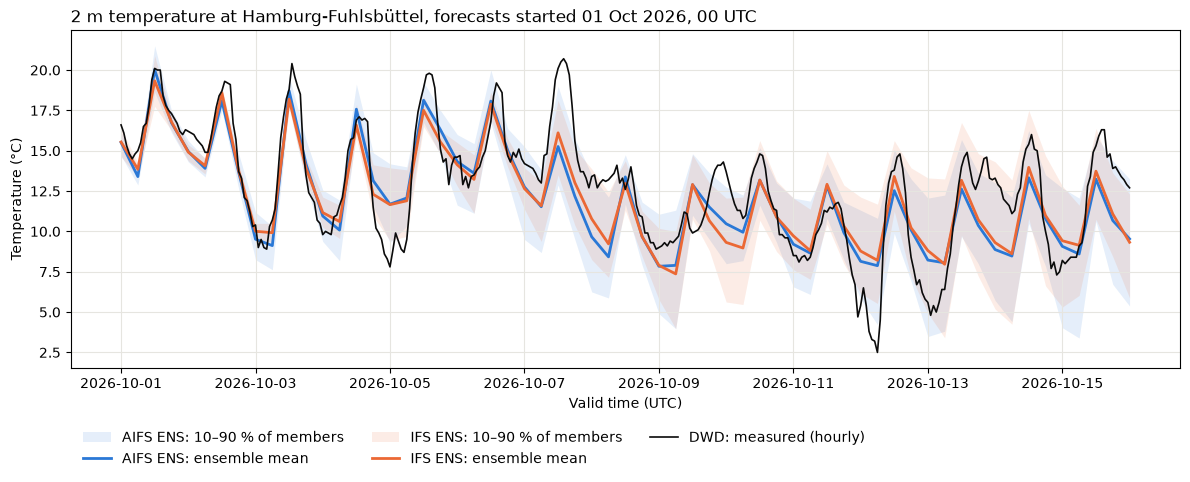

In [27]:
MODEL_COLORS = {"AIFS ENS": "#2a78d6", "IFS ENS": "#eb6834"}
MEASURED_COLOR = "#0b0b0b"
GRID_COLOR = "#e6e5e0"

fig, ax = plt.subplots(figsize=(12, 5))
for name, forecast in [("AIFS ENS", aifs_t2m), ("IFS ENS", ifs_t2m)]:
    t = forecast.valid_time.values # array(['2026-10-01T00:00:00.00', '2026-10-01T06:00:00.00','2026-10-01T12:00:00...]
    band = forecast.quantile([0.1, 0.9], dim="ensemble_member") # retrieve the 10th and 90th percentiles of the ensemble members for each lead time
    ax.fill_between(t, band.sel(quantile=0.1), band.sel(quantile=0.9), # fill the area between the 10th and 90th percentiles
                    color=MODEL_COLORS[name], alpha=0.12, linewidth=0, label=f"{name}: 10–90 % of members")
    ax.plot(t, forecast.mean("ensemble_member"), color=MODEL_COLORS[name], linewidth=2, # plot the actual ensemble mean
            label=f"{name}: ensemble mean")
# plot the measured values from DWD
ax.plot(measured.index, measured.values, color=MEASURED_COLOR, linewidth=1.2, label="DWD: measured (hourly)") 

ax.set_title(f"2 m temperature at {STATION_NAME}, forecasts started {INIT_TIME:%d %b %Y, %H} UTC", loc="left")
ax.set_ylabel("Temperature (°C)")
ax.set_xlabel("Valid time (UTC)")
ax.grid(color=GRID_COLOR, linewidth=0.8)
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.15))
fig.tight_layout()

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / "01_first_look_t2m.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. First integration step: one table

To compare forecasts with measurements, both need the same time axis.
The forecasts have a value every 6 h, the station one every hour,
so for each forecast value we take the measurement at exactly its valid time.
The result is one row per lead time.

In [10]:
table = pd.DataFrame({
    "valid_time": aifs_t2m.valid_time.values,
    "lead_time_h": (aifs_t2m.lead_time.values / np.timedelta64(1, "h")).astype(int),
    "aifs_mean": aifs_t2m.mean("ensemble_member").values,
    "ifs_mean": ifs_t2m.mean("ensemble_member").values,
})
table["measured"] = measured.reindex(pd.DatetimeIndex(table["valid_time"])).values
table.round({"aifs_mean": 2, "ifs_mean": 2}).head(10)

,valid_time,lead_time_h,aifs_mean,ifs_mean,measured
0,2026-10-01 00:00:00,0,15.51,15.540000,16.6
1,2026-10-01 06:00:00,6,13.40,13.850000,15.0
2,2026-10-01 12:00:00,12,20.02,19.330000,20.1
3,2026-10-01 18:00:00,18,16.73,16.790001,17.3
4,2026-10-02 00:00:00,24,14.95,14.910000,16.2
5,2026-10-02 06:00:00,30,13.91,14.070000,14.9
6,2026-10-02 12:00:00,36,18.09,18.580000,18.7
7,2026-10-02 18:00:00,42,13.65,13.750000,13.7
8,2026-10-03 00:00:00,48,9.52,10.010000,10.4
9,2026-10-03 06:00:00,54,9.12,9.920000,10.7


As a first number, the **mean absolute error (MAE)** of each ensemble mean over the lead times +6 h to +360 h:

$$\mathrm{MAE} = \frac{1}{N} \sum_{i=1}^{N} \left| \bar{x}_i - y_i \right|$$

where $N$ denotes the number of lead times that have a measurement, $i$ denotes the index of one lead time,
$\bar{x}_i$ denotes the ensemble-mean forecast at lead time $i$, and $y_i$ denotes the measured temperature
at the matching valid time. The vertical bars $|\cdot|$ take the absolute value, so errors in both directions count as positive.

This single forecast at one station says **nothing** general about which model is better. This only checks that the
pipeline works. The real comparison uses hundreds of forecasts at several stations.

In [11]:
scored = table[(table["lead_time_h"] > 0) & table["measured"].notna()]
for column, name in [("aifs_mean", "AIFS ENS"), ("ifs_mean", "IFS ENS")]:
    mae = (scored[column] - scored["measured"]).abs().mean()
    print(f"{name}: MAE = {mae:.2f} °C  (N = {len(scored)} lead times)")

AIFS ENS: MAE = 1.68 °C  (N = 60 lead times)
IFS ENS: MAE = 1.58 °C  (N = 60 lead times)


## Next steps

- Many forecasts (every 00 UTC start since July 2025) instead of one.
- Several stations, and interpolation to the exact station position instead of the nearest grid point.
- More variables: 10 m wind and precipitation.
- Error as a function of lead time (research question 1).
- Significance of the difference between the two models (research question 2).